# Modelo completo de abandono de clientes

Un único flujo para explorar los datos, elegir la preparación, comparar 12 modelos, ajustar tres candidatos y exportar el modelo final. Integra los notebooks 01–04; el 00 queda como auditoría independiente y el 05 como control histórico.

**Uso habitual:** selecciona el entorno del proyecto y pulsa **Restart → Run All**. Solo se necesita `data/original/Customer Churn.csv`; los datos, decisiones y candidatos pasan en memoria entre secciones.

1. **Datos y exploración:** partición estratificada 80/20, semilla 42.
2. **Preparación:** escalado, PCA y ANOVA con diez particiones de validación.
3. **Comparación:** 41 combinaciones, tres candidatos por F1.
4. **Ajuste y evaluación:** ajuste sobre train, evaluación final sobre test y exportación.

**Archivos:** por defecto se exportan el modelo, sus metadatos y tres CSV que necesita la app (train, test y priorización). Las tablas y figuras se muestran dentro del cuaderno; su exportación separada es opcional.

**Reanudar:** activa `GUARDAR_PUNTO_COMPARACION` en una ejecución completa. Después puedes activar `REANUDAR_COMPARACION` y ejecutar todo para saltar exploración, preparación y comparación. El punto conserva los datos y candidatos; debe regenerarse si cambias código, datos o dependencias. Con el kernel activo también puedes volver a ejecutar una sección y las posteriores.

Se conserva la metodología de los originales. La partición admite perfiles repetidos entre conjuntos. La selección y el umbral no tienen validación anidada; el calibrador ajustado con puntajes fuera de pliegue se conserva para aplicar el umbral. La unificación no elimina esas limitaciones ni incorpora los controles históricos del 05. Colab requiere configurar la ruta y no está validado.

## Configuración

Define rutas y exportaciones antes de ejecutar. La opción de reanudación requiere un punto guardado con este mismo cuaderno.

In [47]:
EN_COLAB = False
GUARDAR_TABLAS = False
GUARDAR_FIGURAS = False
GUARDAR_PUNTO_COMPARACION = False
REANUDAR_COMPARACION = False

if EN_COLAB:
    %pip install phik imbalanced-learn -q
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/churn/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_MODELOS = RUTA_BASE + "models/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
RUTA_FIGURAS = RUTA_BASE + "figuras/"
RUTA_PUNTO = RUTA_MODELOS + "punto_comparacion_churn.joblib"


## Importaciones

Las dependencias se cargan una sola vez. En local se utiliza el entorno existente del proyecto.

In [48]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
from sklearn.model_selection import train_test_split
import joblib
from sklearn.base import clone
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import time
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier
import json
import datetime
import sklearn
import imblearn
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import brier_score_loss
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve
import hashlib
import sys
from pathlib import Path
from sklearn.model_selection import ParameterGrid
from IPython.display import display

for ruta in [RUTA_MODELOS, RUTA_RESULTADOS, RUTA_FIGURAS]:
    os.makedirs(ruta, exist_ok=True)
ruta_original = RUTA_DATOS + "original/Customer Churn.csv"
huella_datos = hashlib.sha256(Path(ruta_original).read_bytes()).hexdigest()
VERSION_FLUJO = "b41f41b35b84eb41b5a63dc040f6ccd46e62c55fc2dd081538e137eb38fa89fe"
versiones = {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "imblearn": imblearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}


## Funciones compartidas

Las cuatro etapas utilizan las mismas funciones. El catálogo incluye una grilla para cada uno de los doce modelos, por lo que el ajuste admite cualquier candidato seleccionado.

In [49]:
def crear_escalador(nombre):
    """
    Devuelve la instancia del escalador solicitado según su nombre.
    Si se indica 'Sin escalar', devuelve 'passthrough'.
    """
    if nombre == "StandardScaler":
        return StandardScaler()
    elif nombre == "MinMaxScaler":
        return MinMaxScaler()
    elif nombre == "Sin escalar":
        return "passthrough"
    else:
        raise ValueError(f"Escalador no reconocido: {nombre}")

def crear_pipeline(nombre_escalador, transformador):
    """
    Construye un Pipeline con un escalador, un transformador opcional (PCA, selector o passthrough)
    y el clasificador de referencia (LogisticRegression balanceada).
    """
    return Pipeline([
        ("escalador", crear_escalador(nombre_escalador)),
        ("transformador", transformador),
        ("modelo", LogisticRegression(
            class_weight="balanced",
            solver="liblinear",
            max_iter=2000,
            random_state=42
        ))
    ])

def evaluar_cv(pipeline, X, y, particiones, metricas, nombre):
    """
    Evalúa el pipeline recibido usando validación cruzada.
    Devuelve un diccionario con el F1 promedio, su desviación estándar, precisión y recall.
    """
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=particiones,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    return {
        "Nombre": nombre,
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(ddof=1),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    }


### Catálogo de modelos y espacios de ajuste

Las grillas incluyen la configuración base y alternativas acotadas. Los modelos y sus nombres se definen una sola vez.

In [50]:
def crear_modelos():
    """
    Devuelve los 12 modelos que comparamos, como parejas (nombre, estimador sin entrenar).
    """
    modelos = [
        ("KNN", KNeighborsClassifier(n_neighbors=5)),
        ("Naive Bayes", GaussianNB()),
        ("Árbol de decisión", DecisionTreeClassifier(random_state=42)),
        ("Regresión logística", LogisticRegression(max_iter=2000, random_state=42)),
        ("SVM", SVC(random_state=42)),
        ("SVM lineal", LinearSVC(max_iter=10000, random_state=42)),
        ("Red neuronal (MLP)", MLPClassifier(max_iter=1000, random_state=42)),
        ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=42)),
        ("Bagging", BaggingClassifier(random_state=42)),
        ("AdaBoost", AdaBoostClassifier(random_state=42)),
        ("Gradient Boosting", GradientBoostingClassifier(random_state=42)),
        ("Stacking", StackingClassifier(
            estimators=[
                ("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
                ("svm", SVC(random_state=42)),
                ("knn", KNeighborsClassifier(n_neighbors=5))
            ],
            final_estimator=LogisticRegression(max_iter=2000),
            cv=5
        ))
    ]
    return modelos

def buscar_modelo(nombre):
    """Obtiene un modelo nuevo del catálogo compartido."""
    for nombre_modelo, modelo in crear_modelos():
        if nombre_modelo == nombre:
            return modelo
    raise ValueError(f"Modelo no reconocido: {nombre}")


def obtener_grilla(nombre_modelo, estrategia):
    """Devuelve el espacio de búsqueda para GridSearchCV."""
    grillas = {
        "KNN": {"modelo__n_neighbors": [3, 5, 9]},
        "Naive Bayes": {"modelo__var_smoothing": [1e-9, 1e-8]},
        "Árbol de decisión": {"modelo__max_depth": [None, 10], "modelo__min_samples_leaf": [1, 2]},
        "Regresión logística": {"modelo__C": [0.1, 1.0, 10.0]},
        "SVM": {"modelo__C": [0.1, 1.0, 10.0]},
        "SVM lineal": {"modelo__C": [0.1, 1.0, 10.0]},
        "AdaBoost": {"modelo__n_estimators": [50, 100], "modelo__learning_rate": [0.5, 1.0]},
        "Gradient Boosting": {"modelo__n_estimators": [100, 200], "modelo__learning_rate": [0.05, 0.1]},
        "Random Forest": {
            "modelo__n_estimators": [200, 300],
            "modelo__max_depth": [10, 15, None],
            "modelo__min_samples_leaf": [1, 2]
        },
        "Stacking": {
            "modelo__final_estimator__C": [0.1, 1.0, 10.0]
        },
        "Bagging": {
            "modelo__n_estimators": [10, 50],
            "modelo__max_samples": [0.7, 1.0]
        },
        "Red neuronal (MLP)": {
            "modelo__hidden_layer_sizes": [(100,), (100, 50)],
            "modelo__alpha": [0.0001, 0.001]
        }
    }
    grilla = grillas[nombre_modelo].copy()
    if estrategia == "SMOTENC":
        grilla["balanceo__k_neighbors"] = [3, 5]
    return grilla


### Balanceo, pipelines y comparación

El balanceo se ejecuta dentro de cada pliegue y antes de la transformación elegida. Se conserva el escalador aunque la opción sea «Sin escalar».

In [51]:
def admite_class_weight(modelo):
    """Comprueba si el modelo tiene el hiperparámetro class_weight."""
    return hasattr(modelo, "class_weight")

def crear_balanceador(estrategia, posiciones_categoricas):
    """Devuelve el remuestreador correspondiente según la estrategia seleccionada."""
    if estrategia == "Sin balanceo" or estrategia == "class_weight":
        return None
    elif estrategia == "SMOTENC":
        return SMOTENC(categorical_features=posiciones_categoricas, random_state=42)
    elif estrategia == "Submuestreo":
        return RandomUnderSampler(random_state=42)
    else:
        raise ValueError(f"Estrategia no reconocida: {estrategia}")

def armar_pipeline(plantilla, modelo, estrategia, posiciones_categoricas):
    """Construye el pipeline en orden escalador, balanceador, transformador y modelo."""
    preparacion = clone(plantilla)
    pasos = [("escalador", preparacion.named_steps["escalador"])]
    balanceador = crear_balanceador(estrategia, posiciones_categoricas)
    if balanceador is not None:
        pasos.append(("balanceo", balanceador))

    pasos.append(("transformador", preparacion.named_steps["transformador"]))
    modelo_clonado = clone(modelo)
    if estrategia == "class_weight":
        modelo_clonado.set_params(class_weight="balanced")

    pasos.append(("modelo", modelo_clonado))
    return Pipeline(pasos)

def evaluar_combinacion(pipeline, X, y, particiones, metricas, etiqueta):
    """
    Evalúa una combinación de modelo y estrategia en las 10 particiones de CV.
    Registra el tiempo de cómputo y el promedio de cada métrica.
    """
    inicio = time.time()
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=particiones,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )
    tiempo_total = time.time() - inicio

    return {
        "Combinacion": etiqueta,
        "F1": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(ddof=1),
        "F1_por_particion": scores["test_f1"],
        "Recall": scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean(),
        "Accuracy": scores["test_accuracy"].mean(),
        "Tiempo_s": tiempo_total
    }


### Control de categorías

Verificamos las categorías después de SMOTENC; el control admite ausencia de escalado y ausencia de transformación, además de ANOVA o PCA.

In [52]:
def verificar_categorias_smotenc(plantilla, X, y, particiones, posiciones_categoricas):
    """Verifica las categorías remuestreadas antes del selector en cada pliegue."""
    rows = []
    for numero, (indices_tr, indices_val) in enumerate(particiones):
        X_pliegue = X.iloc[indices_tr]
        y_pliegue = y.iloc[indices_tr]
        pipeline = armar_pipeline(
            plantilla, LogisticRegression(), "SMOTENC", posiciones_categoricas
        )
        escalador = pipeline.named_steps["escalador"]
        if isinstance(escalador, str) and escalador == "passthrough":
            X_escalado = X_pliegue.to_numpy(copy=True)
        else:
            X_escalado = escalador.fit_transform(X_pliegue)
        if X_escalado.shape[1] != X.shape[1]:
            raise ValueError("El escalador cambió la cantidad de columnas antes de SMOTENC.")
        X_balanceado, y_balanceado = pipeline.named_steps["balanceo"].fit_resample(
            X_escalado, y_pliegue
        )
        if isinstance(escalador, str) and escalador == "passthrough":
            X_original = np.asarray(X_balanceado)
        else:
            X_original = escalador.inverse_transform(X_balanceado)
        transformador = pipeline.named_steps["transformador"]
        if isinstance(transformador, str) and transformador == "passthrough":
            X_seleccionado = X_balanceado
        else:
            X_seleccionado = transformador.fit_transform(X_balanceado, y_balanceado)
        for posicion in posiciones_categoricas:
            columna = X.columns[posicion]
            validos = np.zeros(len(X_original), dtype=bool)
            for valor in X_pliegue[columna].unique():
                validos = validos | np.isclose(X_original[:, posicion], valor)
            invalidos = int((~validos).sum())
            if invalidos > 0:
                raise ValueError("SMOTENC generó categorías inválidas en " + columna)
            rows.append({
                "Pliegue": numero + 1,
                "Columna": columna,
                "Posicion_SMOTENC": posicion,
                "Entradas_SMOTENC": X_escalado.shape[1],
                "Entradas_tras_transformacion": X_seleccionado.shape[1],
                "Valores_invalidos": invalidos
            })
    return pd.DataFrame(rows)


### Puntajes, calibración y métricas

La calibración sigmoide se ajusta con puntajes fuera de pliegue y se conserva al reentrenar el modelo base. Las métricas de selección usan train y no son una estimación independiente; test se usa al final.

In [53]:
def obtener_puntaje(pipeline, X):
    """
    Devuelve un puntaje continuo para cada fila: la función de decisión si existe,
    o el logit de la probabilidad estimada (clip a [1e-6, 1 - 1e-6]).
    """
    if hasattr(pipeline, "decision_function"):
        return np.asarray(pipeline.decision_function(X)).ravel()
    prob = np.clip(pipeline.predict_proba(X)[:, 1], 1e-6, 1.0 - 1e-6)
    return np.log(prob / (1.0 - prob))

def predecir_probabilidad(resultado_candidato, X):
    """Genera probabilidades calibradas pasando el puntaje del pipeline por el calibrador sigmoide."""
    puntajes = obtener_puntaje(resultado_candidato["pipeline"], X)
    return resultado_candidato["calibrador"].predict_proba(puntajes.reshape(-1, 1))[:, 1]

def calcular_metricas(y_real, y_pred, probabilidades):
    """Calcula el conjunto completo de métricas de clasificación y calibración."""
    return {
        "F1": f1_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_real, probabilidades),
        "Precision_promedio": average_precision_score(y_real, probabilidades),
        "Accuracy": accuracy_score(y_real, y_pred),
        "Brier": brier_score_loss(y_real, probabilidades)
    }


### Ajuste de cada candidato

GridSearchCV utiliza precisión promedio. La comparación final de candidatos y la selección del umbral utilizan F1, como en el notebook 04 original.

In [54]:
def ajustar_candidato(pipeline_base, grilla, X, y, particiones):
    """
    Ajusta hiperparámetros con GridSearchCV, calibra con predicciones fuera de pliegue
    y encuentra el umbral óptimo de decisión.
    """
    # 1. Búsqueda de hiperparámetros
    grid = GridSearchCV(
        pipeline_base,
        param_grid=grilla,
        cv=particiones,
        scoring="average_precision",
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )
    grid.fit(X, y)
    mejor_pipeline = grid.best_estimator_

    # 2. Generación de puntajes fuera de pliegue para calibración
    puntajes_oof = np.zeros(len(y))
    for indices_tr, indices_val in particiones:
        pipe_pliegue = clone(mejor_pipeline)
        pipe_pliegue.fit(X.iloc[indices_tr], y.iloc[indices_tr])
        puntajes_oof[indices_val] = obtener_puntaje(pipe_pliegue, X.iloc[indices_val])

    # 3. Ajuste del calibrador sigmoide
    calibrador = LogisticRegression(solver="lbfgs", max_iter=2000)
    calibrador.fit(puntajes_oof.reshape(-1, 1), y)
    probabilidades_cv = calibrador.predict_proba(puntajes_oof.reshape(-1, 1))[:, 1]

    # 4. Búsqueda de umbral óptimo de F1
    umbrales = np.arange(0.05, 0.95, 0.01)
    filas_umbral = []
    mejor_f1 = -1.0
    mejor_umbral = 0.50

    for u in umbrales:
        pred_u = (probabilidades_cv >= u).astype(int)
        f1_u = f1_score(y, pred_u, zero_division=0)
        rec_u = recall_score(y, pred_u, zero_division=0)
        prec_u = precision_score(y, pred_u, zero_division=0)
        filas_umbral.append({"Umbral": u, "F1": f1_u, "Recall": rec_u, "Precision": prec_u})
        if f1_u > mejor_f1:
            mejor_f1 = f1_u
            mejor_umbral = u

    # 5. Ajuste final con todo el conjunto de entrenamiento
    mejor_pipeline.fit(X, y)
    # Conservamos el calibrador OOF con el que se seleccionó el umbral.
    # Reajustarlo con puntajes de entrenamiento cambiaría la escala de probabilidades.

    return {
        "pipeline": mejor_pipeline,
        "calibrador": calibrador,
        "parametros": grid.best_params_,
        "umbral": round(float(mejor_umbral), 2),
        "probabilidades_cv": probabilidades_cv,
        "tabla_umbrales": pd.DataFrame(filas_umbral)
    }


## 1. Datos y exploración

Leemos únicamente el archivo original. El análisis detallado utiliza train. Las cifras y gráficas siguientes se regeneran en cada ejecución completa.

### Carga y exploración inicial de los datos

Leemos el archivo original de datos `Customer Churn.csv` sin modificarlo. Verificamos su tamaño, tipos de datos, presencia de valores faltantes y registros duplicados.

In [55]:
if not REANUDAR_COMPARACION:
    ruta_original = RUTA_DATOS + "original/Customer Churn.csv"
    datos_originales = pd.read_csv(ruta_original)

    print("Dimensiones del dataset:", datos_originales.shape)
    print("Valores faltantes por columna:\n", datos_originales.isna().sum())
    print("Filas duplicadas exactas:", datos_originales.duplicated().sum())

    print("\nInformación general de columnas:")
    datos_originales.info()

    print("\nPrimeras 5 filas:")
    datos_originales.head()


Dimensiones del dataset: (3150, 14)
Valores faltantes por columna:
 Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64
Filas duplicadas exactas: 300

Información general de columnas:
<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use          

Encontramos un total de 3.150 registros y 14 columnas, sin ningún valor faltante en ninguna variable.
Existen 300 filas repetidas; al no contar con un identificador único de cliente (como documento o ID de cuenta), estas repeticiones representan perfiles de clientes con mediciones de uso idénticas, por lo que las conservamos tal como indica el análisis del problema.

### Renombrado y selección inicial de variables

Renombramos las columnas a español y en minúsculas para mantener un código claro y legible.
Excluimos las columnas `Status` y `Customer Value` porque no se tiene certeza sobre su definición temporal en el negocio y podrían generar inconsistencias. Conservamos las 11 variables de entrada restantes más la variable objetivo `abandono`.

In [56]:
if not REANUDAR_COMPARACION:
    nombres = {
        "Call  Failure": "fallas_llamadas",
        "Complains": "quejas",
        "Subscription  Length": "antiguedad",
        "Charge  Amount": "nivel_cargo",
        "Seconds of Use": "segundos_uso",
        "Frequency of use": "frecuencia_uso",
        "Frequency of SMS": "frecuencia_sms",
        "Distinct Called Numbers": "numeros_distintos",
        "Age Group": "grupo_edad",
        "Tariff Plan": "plan_tarifario",
        "Status": "estado",
        "Age": "edad",
        "Customer Value": "valor_cliente",
        "Churn": "abandono"
    }

    datos = datos_originales.rename(columns=nombres).copy()
    datos = datos.drop(columns=["estado", "valor_cliente"])

    X = datos.drop(columns="abandono")
    y = datos["abandono"]

    print("Cantidad de variables de entrada (X):", X.shape[1])
    print("Total de filas conservadas:", len(datos))
    print("\nDistribución de la variable objetivo:")
    print(y.value_counts())


Cantidad de variables de entrada (X): 11
Total de filas conservadas: 3150

Distribución de la variable objetivo:
abandono
0    2655
1     495
Name: count, dtype: int64


Conservamos 3.150 registros con 11 variables de entrada y la variable objetivo `abandono`.
En el conjunto completo hay 495 casos de abandono (15,71 %) y 2.655 de permanencia (84,29 %).

### Partición de entrenamiento y prueba (80/20 estratificada)

Siguiendo la metodología de clase, dividimos los datos en 80 % para entrenamiento y 20 % para prueba usando `train_test_split`.
Fijamos `stratify=y` para que ambos subconjuntos conserven exactamente la misma proporción de clientes que abandonaron, y `random_state=42` para que la partición sea completamente reproducible.

El conjunto de prueba (`test`) se reserva desde este momento y no se utiliza en ninguna decisión de preprocesamiento, análisis o modelado hasta la evaluación final del sección final.

In [57]:
if not REANUDAR_COMPARACION:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    train = pd.concat([X_train, y_train], axis=1)
    test = pd.concat([X_test, y_test], axis=1)

    print("Filas de entrenamiento (train):", len(train))
    print("Filas de prueba (test):", len(test))

    # Verificamos la distribución de la clase en ambos conjuntos
    rows = []
    for nombre_set, serie_y in [("Completo", y), ("Train", y_train), ("Test", y_test)]:
        conteo_0 = int((serie_y == 0).sum())
        conteo_1 = int((serie_y == 1).sum())
        prop_1 = (serie_y == 1).mean() * 100
        rows.append({
            "Conjunto": nombre_set,
            "Total": len(serie_y),
            "Permanencia (0)": conteo_0,
            "Abandono (1)": conteo_1,
            "% Abandono": round(prop_1, 2)
        })

    tabla_particion = pd.DataFrame(rows)
    print("\nVerificación de estratificación:")
    display(tabla_particion)

    indices_train_originales = X_train.index.to_numpy(copy=True)
    indices_test_originales = X_test.index.to_numpy(copy=True)
    train = train.reset_index(drop=True)
    test = test.reset_index(drop=True)
    X_train = train.drop(columns="abandono")
    y_train = train["abandono"]
    X_test = test.drop(columns="abandono")
    y_test = test["abandono"]


Filas de entrenamiento (train): 2520
Filas de prueba (test): 630

Verificación de estratificación:


,Conjunto,Total,Permanencia (0),Abandono (1),% Abandono
0,Completo,3150,2655,495,15.71
1,Train,2520,2124,396,15.71
2,Test,630,531,99,15.71


La partición 80/20 deja exactamente 2.520 filas de entrenamiento y 630 filas de prueba. En ambas particiones la proporción de abandono es del 15,71 % (396 abandonos en entrenamiento y 99 en prueba). A partir de aquí todo el análisis se realiza exclusivamente sobre `train`.

### Revisión de variables en entrenamiento

Revisamos los tipos de datos, cantidad de valores únicos, valores mínimos, máximos y valores faltantes de cada columna en el conjunto de entrenamiento.

In [58]:
if not REANUDAR_COMPARACION:
    rows = []
    for columna in train.columns:
        serie = train[columna]
        rows.append({
            "Columna": columna,
            "Tipo": str(serie.dtype),
            "Valores únicos": serie.nunique(),
            "Mínimo": serie.min(),
            "Máximo": serie.max(),
            "Nulos": serie.isna().sum()
        })

    tabla_revision = pd.DataFrame(rows)
    display(tabla_revision)


,Columna,Tipo,Valores únicos,Mínimo,Máximo,Nulos
0,fallas_llamadas,int64,37,0,36,0
1,quejas,int64,2,0,1,0
2,antiguedad,int64,45,3,47,0
3,nivel_cargo,int64,11,0,10,0
4,segundos_uso,int64,1528,0,16980,0
5,frecuencia_uso,int64,238,0,254,0
6,frecuencia_sms,int64,382,0,522,0
7,numeros_distintos,int64,92,0,97,0
8,grupo_edad,int64,5,1,5,0
9,plan_tarifario,int64,2,1,2,0


Las escalas son distintas; en la siguiente etapa compararemos si escalar mejora el modelo de referencia.

### Distribución de la variable objetivo

Analizamos la proporción de clientes que permanecen y clientes que abandonan en el conjunto de entrenamiento.

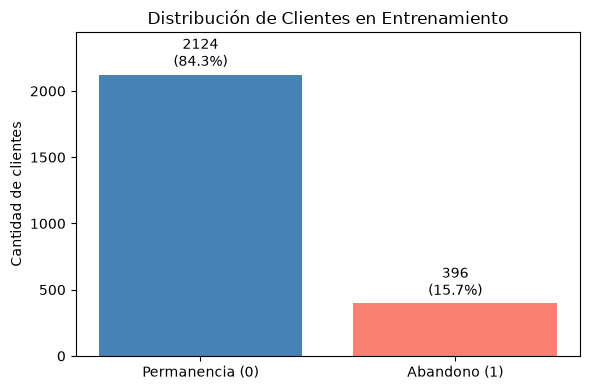

Total permanencia (0): 2124 (84.29%)
Total abandono (1):    396 (15.71%)


In [59]:
if not REANUDAR_COMPARACION:
    conteo = y_train.value_counts().reindex([0, 1], fill_value=0)
    porcentajes = (conteo / len(y_train)) * 100

    fig, ax = plt.subplots(figsize=(6, 4))
    barras = ax.bar(["Permanencia (0)", "Abandono (1)"], conteo, color=["steelblue", "salmon"])
    ax.set_title("Distribución de Clientes en Entrenamiento")
    ax.set_ylabel("Cantidad de clientes")

    for barra, porcentaje in zip(barras, porcentajes):
        altura = barra.get_height()
        ax.text(barra.get_x() + barra.get_width() / 2, altura + 30, f"{altura}\n({porcentaje:.1f}%)",
                ha="center", va="bottom", fontsize=10)

    ax.set_ylim(0, conteo.max() * 1.15)
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "01_distribucion_clase.png", dpi=150)
    plt.show()

    print(f"Total permanencia (0): {conteo[0]} ({porcentajes[0]:.2f}%)")
    print(f"Total abandono (1):    {conteo[1]} ({porcentajes[1]:.2f}%)")


Encontramos 396 clientes que abandonaron (15,71 %) frente a 2.124 clientes que permanecieron (84,29 %).
Un modelo simple que siempre predijera "permanencia" alcanzaría un accuracy del 84,29 %, pero no detectaría ningún cliente en riesgo de deserción (F1 de abandono = 0). Por eso, el F1 de la clase positiva (`abandono`) será nuestra métrica rectora.

### Análisis de variables categóricas

Examinamos las columnas categóricas: `quejas`, `nivel_cargo`, `grupo_edad` y `plan_tarifario`. Graficamos la cantidad de registros por categoría y el porcentaje de abandono correspondiente.

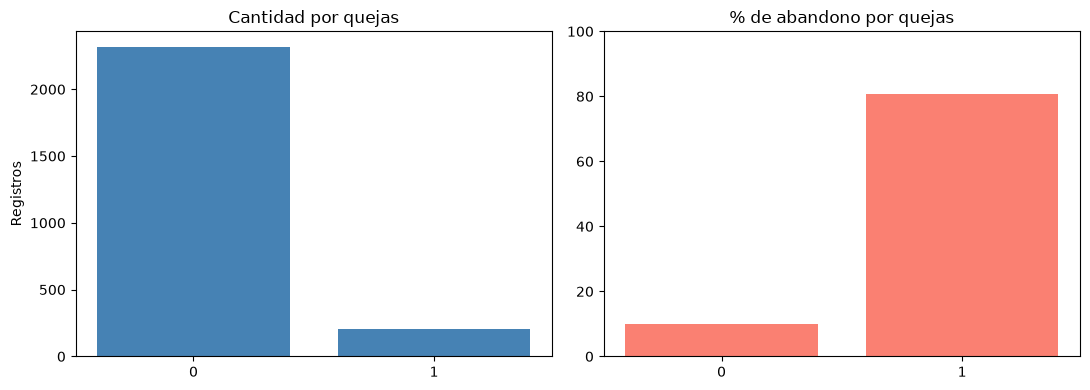

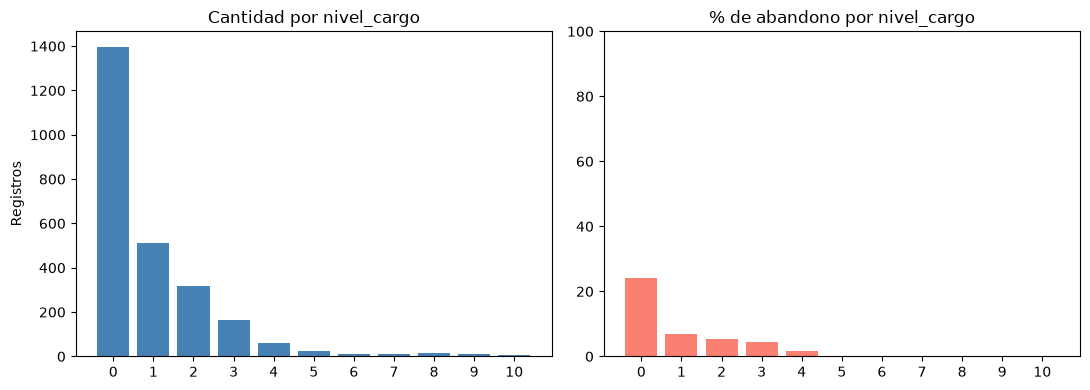

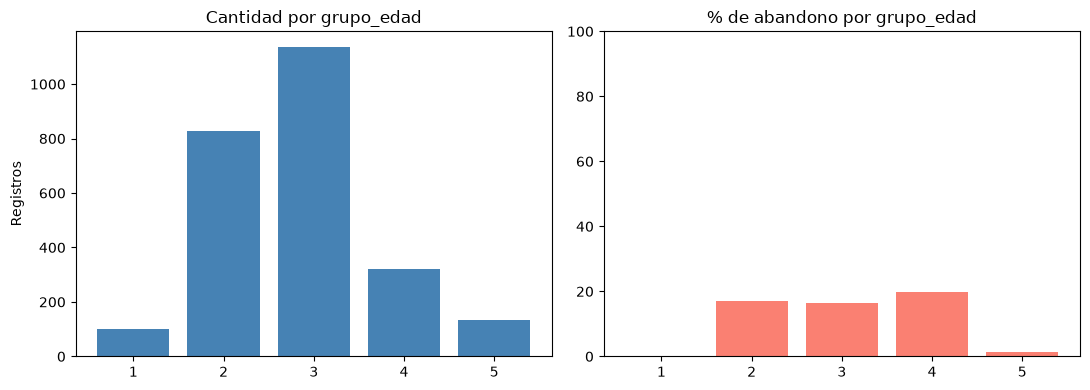

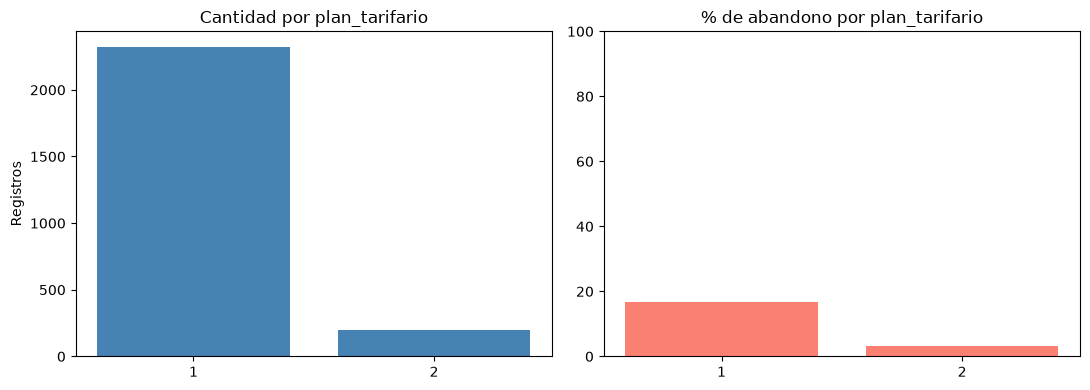

In [60]:
if not REANUDAR_COMPARACION:
    columnas_categoricas = [
        "quejas", "nivel_cargo", "grupo_edad", "plan_tarifario"
    ]

    for columna in columnas_categoricas:
        tabla_cat = train.groupby(columna)["abandono"].agg(["count", "sum"])
        tabla_cat["porcentaje_abandono"] = (tabla_cat["sum"] / tabla_cat["count"]) * 100

        fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

        ejes[0].bar(tabla_cat.index.astype(str), tabla_cat["count"], color="steelblue")
        ejes[0].set_title("Cantidad por " + columna)
        ejes[0].set_ylabel("Registros")

        ejes[1].bar(tabla_cat.index.astype(str), tabla_cat["porcentaje_abandono"], color="salmon")
        ejes[1].set_title("% de abandono por " + columna)
        ejes[1].set_ylim(0, 100)

        plt.tight_layout()
        if GUARDAR_FIGURAS:
            plt.savefig(
                RUTA_FIGURAS + "01_categorica_" + columna + ".png",
                bbox_inches="tight", dpi=150
            )
        plt.show()


Observamos que la variable `quejas` tiene una relación muy fuerte con el abandono: los clientes con quejas registradas presentan una tasa de abandono superior al 80 %, mientras que en los que no presentan quejas la tasa es menor al 10 %. Asimismo, en el `plan_tarifario` 1 el abandono es notablemente más alto que en el plan 2.

### Análisis de variables numéricas

Analizamos la distribución de las variables cuantitativas mediante histogramas, y comparamos el comportamiento de cada una entre permanencia y abandono mediante diagramas de caja.

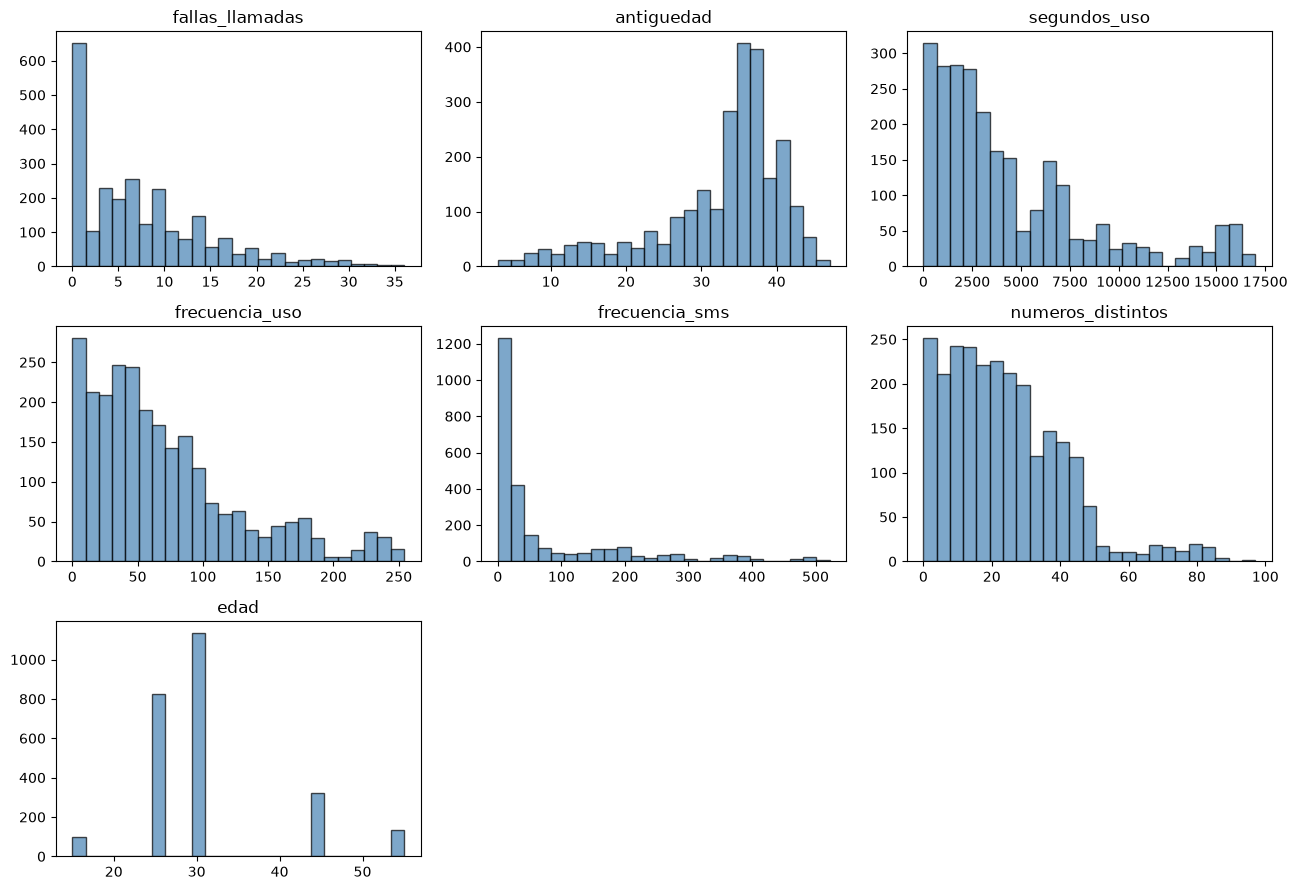

In [61]:
if not REANUDAR_COMPARACION:
    columnas_numericas = []
    for columna in X_train.columns:
        if columna not in columnas_categoricas:
            columnas_numericas.append(columna)

    fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
    ejes = ejes.flatten()

    for i, columna in enumerate(columnas_numericas):
        ejes[i].hist(train[columna], bins=25, color="steelblue", edgecolor="black", alpha=0.7)
        ejes[i].set_title(columna)

    for i in range(len(columnas_numericas), len(ejes)):
        ejes[i].axis("off")

    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "01_histogramas.png", dpi=150)
    plt.show()


Las variables de consumo como `segundos_uso`, `frecuencia_uso` y `frecuencia_sms` presentan una marcada asimetría hacia la derecha: muchos clientes con consumos moderados o bajos y colas extendidas hacia consumos elevados.

Comparamos cada variable numérica entre permanencia (`abandono = 0`) y abandono (`abandono = 1`) usando diagramas de caja.

/var/folders/y4/93gqwfgd1qxbv26dg4yd81ym0000gn/T/ipykernel_32682/4255229409.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/y4/93gqwfgd1qxbv26dg4yd81ym0000gn/T/ipykernel_32682/4255229409.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/y4/93gqwfgd1qxbv26dg4yd81ym0000gn/T/ipykernel_32682/4255229409.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/y4/93gqwfgd1qxbv26dg4yd81ym0000gn/T/ipykernel_32682/4255229409.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

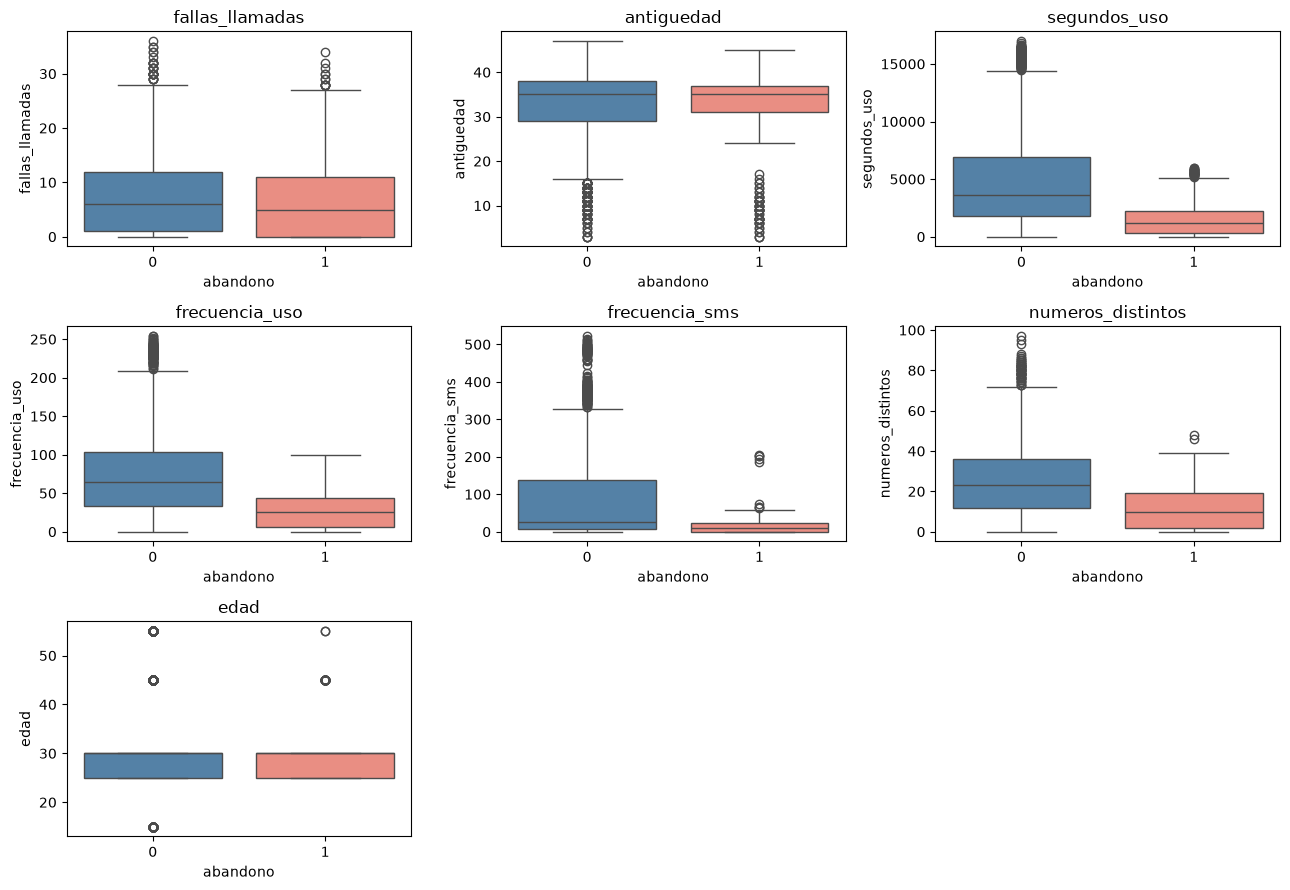

In [62]:
if not REANUDAR_COMPARACION:
    fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
    ejes = ejes.flatten()

    for i, columna in enumerate(columnas_numericas):
        sns.boxplot(
            data=train, x="abandono", y=columna, ax=ejes[i], palette=["steelblue", "salmon"]
        )
        ejes[i].set_title(columna)

    for i in range(len(columnas_numericas), len(ejes)):
        ejes[i].axis("off")

    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "01_boxplots_por_clase.png", dpi=150)
    plt.show()


Los clientes que abandonan presentan medianas claramente más bajas en `segundos_uso`, `frecuencia_uso` y `frecuencia_sms` frente a los clientes que continúan activos. Un bajo consumo del servicio es un indicio claro de posible deserción.

### Asociaciones con phik

Calculamos el coeficiente de correlación phik para evaluar asociaciones lineales y no lineales entre todas las variables de entrada y la variable objetivo `abandono`.

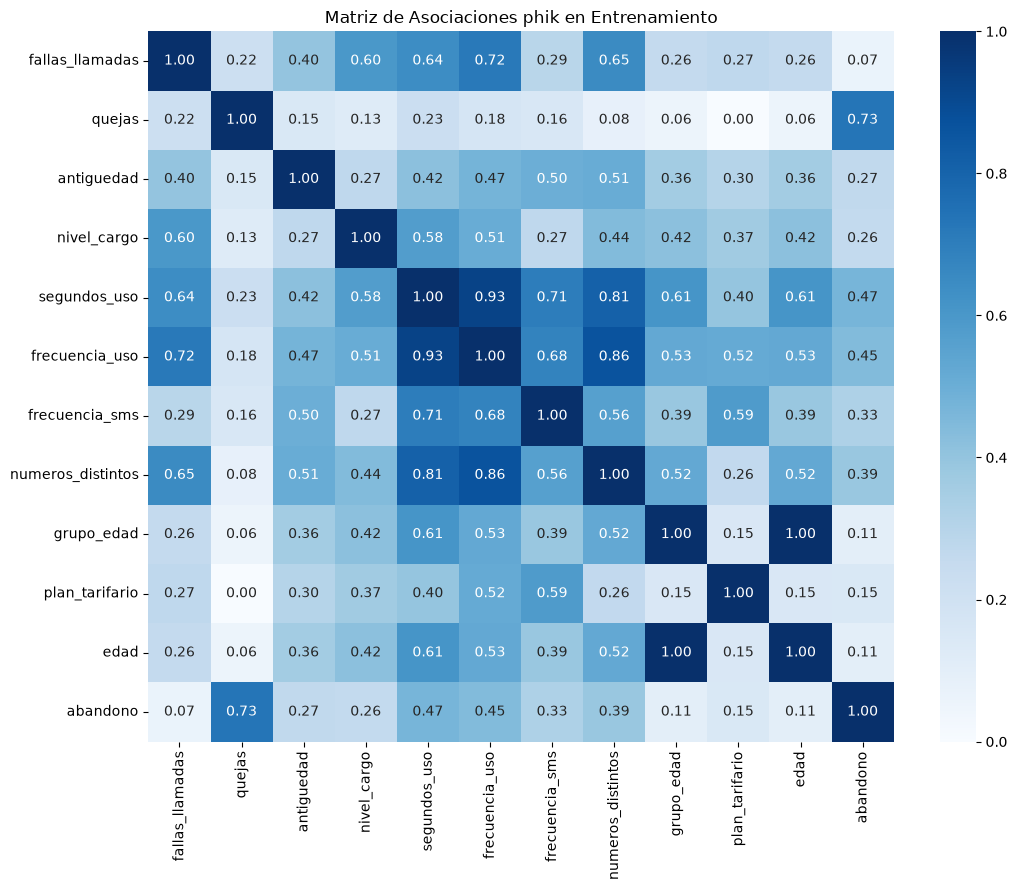

Asociaciones phik con abandono:
quejas               0.734096
segundos_uso         0.468824
frecuencia_uso       0.445167
numeros_distintos    0.388750
frecuencia_sms       0.325001
antiguedad           0.266977
nivel_cargo          0.261715
plan_tarifario       0.152309
grupo_edad           0.105280
edad                 0.105280
fallas_llamadas      0.065747
Name: abandono, dtype: float64


In [63]:
if not REANUDAR_COMPARACION:
    matriz_phik = train.phik_matrix(
        interval_cols=columnas_numericas,
        njobs=1
    )

    plt.figure(figsize=(11, 9))
    sns.heatmap(
        matriz_phik,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1
    )
    plt.title("Matriz de Asociaciones phik en Entrenamiento")
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "01_correlacion_phik.png", dpi=150)
    plt.show()

    if GUARDAR_TABLAS:
        matriz_phik.to_csv(RUTA_RESULTADOS + "01_phik_train.csv")

    print("Asociaciones phik con abandono:")
    print(matriz_phik["abandono"].drop("abandono").sort_values(ascending=False))


La tabla anterior muestra las asociaciones observadas en esta ejecución. La selección formal se realiza en la etapa de preparación.

### Redundancia entre edad y grupo de edad

Revisamos la relación observada en entrenamiento entre las variables `edad` y `grupo_edad`.

In [64]:
if not REANUDAR_COMPARACION:
    relacion_edades = train[["edad", "grupo_edad"]].drop_duplicates().sort_values("edad")
    print("Parejas observadas (edad y grupo de edad):")
    display(relacion_edades)

    print("\nMáximo de grupos distintos por edad:", train.groupby("edad")["grupo_edad"].nunique().max())
    print("Máximo de edades distintas por grupo:", train.groupby("grupo_edad")["edad"].nunique().max())


Parejas observadas (edad y grupo de edad):


,edad,grupo_edad
1,15,1
3,25,2
0,30,3
2,45,4
18,55,5



Máximo de grupos distintos por edad: 1
Máximo de edades distintas por grupo: 1


Observamos cinco parejas únicas: 15-1, 25-2, 30-3, 45-4 y 55-5. Cada valor de edad corresponde exactamente a un grupo de edad y viceversa. Dejamos registrada esta redundancia para evaluarla durante la selección de variables en la sección de preparación.

## 2. Preparación

Comparamos escaladores, PCA y ANOVA sobre el entrenamiento que ya está en memoria. La plantilla elegida se conserva en `decisiones` y `plantilla`; no se guarda ni se vuelve a cargar para continuar.

### Configuración de validación cruzada y métricas

Configuramos una validación cruzada estratificada de 10 particiones (`StratifiedKFold(n_splits=10, shuffle=True, random_state=42)`).
Definimos el $F_1	ext{-score}$ de la clase positiva (`abandono`) como métrica principal, acompañada de precisión y recall.

In [65]:
if not REANUDAR_COMPARACION:
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    particiones_cv = list(cv.split(X_train, y_train))

    metricas = {
        "f1": make_scorer(f1_score, zero_division=0),
        "precision": make_scorer(precision_score, zero_division=0),
        "recall": make_scorer(recall_score, zero_division=0)
    }

    print(f"Validación cruzada lista con {len(particiones_cv)} particiones estratificadas.")


Validación cruzada lista con 10 particiones estratificadas.


### Comparación de escaladores

Evaluamos tres opciones para el escalado de variables:
- Sin escalar (`passthrough`)
- `StandardScaler` (estandarización con media 0 y varianza 1)
- `MinMaxScaler` (escalado al rango [0, 1])

In [66]:
if not REANUDAR_COMPARACION:
    rows = []
    pipelines = {}

    for nombre in ["Sin escalar", "StandardScaler", "MinMaxScaler"]:
        pipeline = crear_pipeline(nombre, "passthrough")
        pipelines[nombre] = pipeline

        fila = evaluar_cv(
            pipeline, X_train, y_train,
            particiones_cv, metricas, nombre
        )

        rows.append(fila)
        print(f"{nombre} -> F1: {fila['F1']:.3f} (± {fila['F1_std']:.3f})")

    tabla_escalado = pd.DataFrame(rows)

    escalador_elegido = tabla_escalado.loc[
        tabla_escalado["F1"].idxmax(), "Nombre"
    ]

    if GUARDAR_TABLAS:
        tabla_escalado.to_csv(
            RUTA_RESULTADOS + "02_comparacion_escaladores.csv",
            index=False
        )

    print(f"\nEscalador con mayor F1: {escalador_elegido}")
    display(tabla_escalado.round(3))


Sin escalar -> F1: 0.604 (± 0.031)
StandardScaler -> F1: 0.603 (± 0.035)
MinMaxScaler -> F1: 0.590 (± 0.036)

Escalador con mayor F1: Sin escalar


,Nombre,F1,F1_std,Precision,Recall
0,Sin escalar,0.604,0.031,0.457,0.891
1,StandardScaler,0.603,0.035,0.458,0.886
2,MinMaxScaler,0.590,0.036,0.447,0.869


La opción con mayor F1 en la tabla anterior se usa como base para ANOVA. PCA se compara con estandarización.

### Análisis de Componentes Principales (PCA)

Analizamos primero la varianza explicada acumulada sobre el conjunto de entrenamiento estandarizado para identificar cuántas componentes resumen la información.

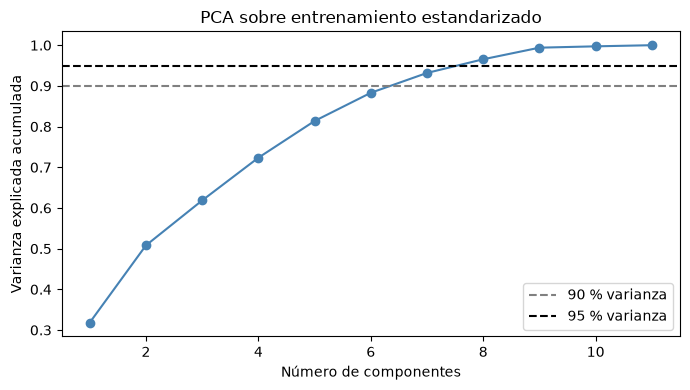

Componentes necesarias para 90 % de varianza: 7
Componentes necesarias para 95 % de varianza: 8


In [67]:
if not REANUDAR_COMPARACION:
    X_escalado = StandardScaler().fit_transform(X_train)

    pca_descriptivo = PCA(svd_solver="full")
    pca_descriptivo.fit(X_escalado)

    varianza_acumulada = np.cumsum(
        pca_descriptivo.explained_variance_ratio_
    )

    plt.figure(figsize=(7, 4))
    plt.plot(
        range(1, len(varianza_acumulada) + 1),
        varianza_acumulada,
        marker="o",
        color="steelblue"
    )
    plt.axhline(0.90, color="gray", linestyle="--", label="90 % varianza")
    plt.axhline(0.95, color="black", linestyle="--", label="95 % varianza")
    plt.xlabel("Número de componentes")
    plt.ylabel("Varianza explicada acumulada")
    plt.title("PCA sobre entrenamiento estandarizado")
    plt.legend()
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "02_pca_varianza.png", dpi=150)
    plt.show()

    n_90 = int(np.argmax(varianza_acumulada >= 0.90)) + 1
    n_95 = int(np.argmax(varianza_acumulada >= 0.95)) + 1
    print(f"Componentes necesarias para 90 % de varianza: {n_90}")
    print(f"Componentes necesarias para 95 % de varianza: {n_95}")


El número de componentes se calcula arriba. A continuación evaluamos PCA dentro del pipeline para compararlo con todas las variables.

In [68]:
if not REANUDAR_COMPARACION:
    rows_pca = []

    for proporcion in [0.90, 0.95]:
        nombre = f"PCA {int(proporcion * 100)}%"

        pipeline = crear_pipeline(
            "StandardScaler",
            PCA(n_components=proporcion, svd_solver="full")
        )

        pipelines[nombre] = pipeline

        fila = evaluar_cv(
            pipeline, X_train, y_train,
            particiones_cv, metricas, nombre
        )

        rows_pca.append(fila)
        print(f"{nombre} -> F1: {fila['F1']:.3f}")

    referencia_pca = tabla_escalado.loc[
        tabla_escalado["Nombre"] == "StandardScaler"
    ]

    tabla_pca = pd.concat(
        [referencia_pca, pd.DataFrame(rows_pca)],
        ignore_index=True
    )

    if GUARDAR_TABLAS:
        tabla_pca.to_csv(
            RUTA_RESULTADOS + "02_comparacion_pca.csv",
            index=False
        )

    display(tabla_pca.round(3))


PCA 90% -> F1: 0.577
PCA 95% -> F1: 0.580


,Nombre,F1,F1_std,Precision,Recall
0,StandardScaler,0.603,0.035,0.458,0.886
1,PCA 90%,0.577,0.034,0.434,0.864
2,PCA 95%,0.580,0.034,0.436,0.866


La tabla anterior compara PCA con la referencia estandarizada. La selección automática se realiza al reunir todas las alternativas.

### Selección de variables con ANOVA (SelectKBest)

Siguiendo el enfoque visto en clase, evaluamos la selección univariada de características usando el test F de ANOVA (`f_classif`) variando el número de características seleccionadas $k$ desde 1 hasta 10.

In [69]:
if not REANUDAR_COMPARACION:
    rows_seleccion = []

    for k in range(1, X_train.shape[1]):
        nombre = f"ANOVA k={k}"

        pipeline = crear_pipeline(
            escalador_elegido,
            SelectKBest(score_func=f_classif, k=k)
        )

        pipelines[nombre] = pipeline

        fila = evaluar_cv(
            pipeline, X_train, y_train,
            particiones_cv, metricas, nombre
        )

        rows_seleccion.append(fila)
        print(f"{nombre} -> F1: {fila['F1']:.3f}")

    tabla_seleccion = pd.DataFrame(rows_seleccion)

    referencia_seleccion = tabla_escalado.loc[
        tabla_escalado["Nombre"] == escalador_elegido
    ]

    tabla_seleccion = pd.concat(
        [referencia_seleccion, tabla_seleccion],
        ignore_index=True
    )

    if GUARDAR_TABLAS:
        tabla_seleccion.to_csv(
            RUTA_RESULTADOS + "02_comparacion_seleccion.csv", index=False
        )
    display(tabla_seleccion.round(3))


ANOVA k=1 -> F1: 0.542
ANOVA k=2 -> F1: 0.535
ANOVA k=3 -> F1: 0.552
ANOVA k=4 -> F1: 0.552
ANOVA k=5 -> F1: 0.561
ANOVA k=6 -> F1: 0.569
ANOVA k=7 -> F1: 0.573
ANOVA k=8 -> F1: 0.571
ANOVA k=9 -> F1: 0.596
ANOVA k=10 -> F1: 0.605


,Nombre,F1,F1_std,Precision,Recall
0,Sin escalar,0.604,0.031,0.457,0.891
1,ANOVA k=1,0.542,0.080,0.808,0.412
2,ANOVA k=2,0.535,0.040,0.405,0.793
3,ANOVA k=3,0.552,0.034,0.418,0.816
4,ANOVA k=4,0.552,0.042,0.416,0.826
5,ANOVA k=5,0.561,0.047,0.421,0.846
6,ANOVA k=6,0.569,0.043,0.430,0.849
7,ANOVA k=7,0.573,0.044,0.433,0.851
8,ANOVA k=8,0.571,0.045,0.431,0.851
9,ANOVA k=9,0.596,0.034,0.455,0.871


### Comparación general de alternativas de preprocesamiento

Reunimos todas las alternativas evaluadas (escaladores, PCA y selecciones ANOVA) y graficamos el F1 promedio obtenido por cada una junto con su desviación estándar entre particiones.

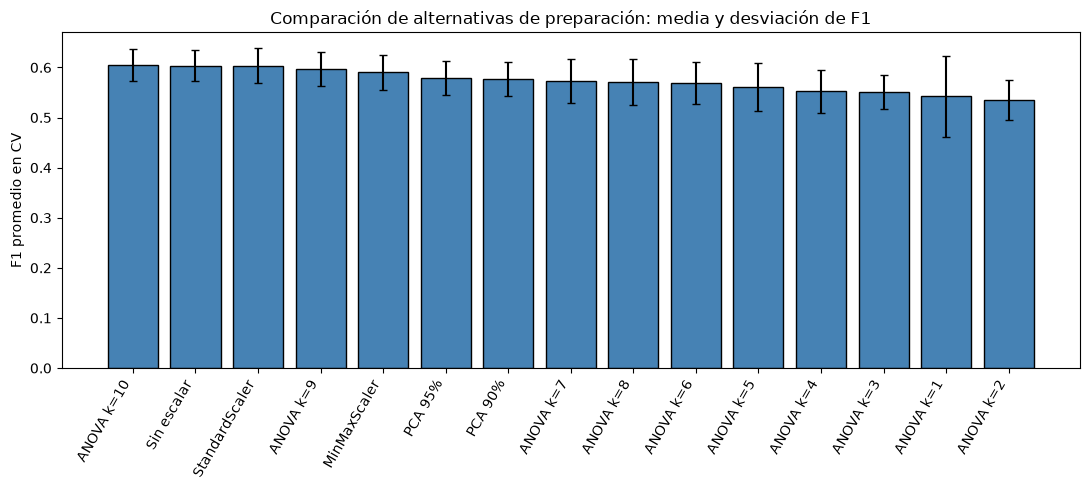

Alternativa seleccionada con mayor F1: ANOVA k=10


,Nombre,F1,F1_std,Precision,Recall
14,ANOVA k=10,0.605,0.032,0.460,0.889
0,Sin escalar,0.604,0.031,0.457,0.891
1,StandardScaler,0.603,0.035,0.458,0.886
13,ANOVA k=9,0.596,0.034,0.455,0.871
2,MinMaxScaler,0.590,0.036,0.447,0.869
4,PCA 95%,0.580,0.034,0.436,0.866
3,PCA 90%,0.577,0.034,0.434,0.864
11,ANOVA k=7,0.573,0.044,0.433,0.851
12,ANOVA k=8,0.571,0.045,0.431,0.851
10,ANOVA k=6,0.569,0.043,0.430,0.849


In [70]:
if not REANUDAR_COMPARACION:
    comparacion = pd.concat(
        [
            tabla_escalado,
            pd.DataFrame(rows_pca),
            pd.DataFrame(rows_seleccion)
        ],
        ignore_index=True
    )

    nombre_elegido = comparacion.loc[
        comparacion["F1"].idxmax(), "Nombre"
    ]

    if GUARDAR_TABLAS:
        comparacion.to_csv(
            RUTA_RESULTADOS + "comparacion_rasgos.csv",
            index=False
        )

    tabla_ordenada = comparacion.sort_values(
        "F1", ascending=False, kind="stable"
    )

    plt.figure(figsize=(11, 5))
    plt.bar(
        tabla_ordenada["Nombre"],
        tabla_ordenada["F1"],
        yerr=tabla_ordenada["F1_std"],
        capsize=3,
        color="steelblue",
        edgecolor="black"
    )
    plt.xticks(rotation=60, ha="right")
    plt.ylabel("F1 promedio en CV")
    plt.title("Comparación de alternativas de preparación: media y desviación de F1")
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "02_comparacion_rasgos.png", dpi=150)
    plt.show()

    print(f"Alternativa seleccionada con mayor F1: {nombre_elegido}")
    display(tabla_ordenada.round(3))


La alternativa se elige por el mayor F1 observado, sin imponer un escalador ni un número fijo de variables.

### Preparación elegida en memoria

Conservamos una plantilla sin ajustar y una única definición de las diez particiones para el resto del flujo.

In [71]:
if not REANUDAR_COMPARACION:
    pipeline_elegido = pipelines[nombre_elegido]

    # Extraemos únicamente los pasos de transformación previos al clasificador
    preprocesamiento = clone(pipeline_elegido[:-1])

    decisiones = {
        "alternativa": nombre_elegido,
        "columnas_entrada": list(X_train.columns),
        "preprocesamiento": preprocesamiento,
        "modelo_referencia": "RegresionLogisticaBalanced",
        "metrica_principal": "f1",
        "validacion": "StratifiedKFold",
        "n_splits": 10,
        "random_state": 42
    }


    plantilla = decisiones["preprocesamiento"]
    columnas_entrada = list(X_train.columns)
    display(tabla_ordenada.head(1).round(4))


,Nombre,F1,F1_std,Precision,Recall
14,ANOVA k=10,0.6051,0.0324,0.46,0.889


## 3. Comparación de modelos

Evaluamos las mismas 41 combinaciones sobre las particiones ya definidas. El orden es escalador → balanceo → transformación elegida → modelo; SMOTENC ve las categorías antes de PCA o ANOVA.

In [72]:
if not REANUDAR_COMPARACION:
    metricas = {
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }

    # Identificamos los índices de las columnas categóricas para SMOTENC
    COLUMNAS_CATEGORICAS = ["quejas", "plan_tarifario"]
    posiciones_cat = []
    for i, col in enumerate(X_train.columns):
        if col in COLUMNAS_CATEGORICAS:
            posiciones_cat.append(i)

    print(f"Particiones de CV: {len(particiones_cv)}")
    print("Posiciones de variables categóricas:", posiciones_cat)


Particiones de CV: 10
Posiciones de variables categóricas: [1, 9]


### Comprobación del recorrido de las categorías

Se comprueban los diez pliegues usando solo train.

In [73]:
if not REANUDAR_COMPARACION:
    control_categorias = verificar_categorias_smotenc(
        plantilla, X_train, y_train, particiones_cv, posiciones_cat
    )
    if GUARDAR_TABLAS:
        control_categorias.to_csv(
            RUTA_RESULTADOS + "03_control_categorias_smotenc.csv", index=False
        )
    display(control_categorias)


,Pliegue,Columna,Posicion_SMOTENC,Entradas_SMOTENC,Entradas_tras_transformacion,Valores_invalidos
0,1,quejas,1,11,10,0
1,1,plan_tarifario,9,11,10,0
2,2,quejas,1,11,10,0
3,2,plan_tarifario,9,11,10,0
4,3,quejas,1,11,10,0
5,3,plan_tarifario,9,11,10,0
6,4,quejas,1,11,10,0
7,4,plan_tarifario,9,11,10,0
8,5,quejas,1,11,10,0
9,5,plan_tarifario,9,11,10,0


### Combinaciones compatibles

Se excluye class_weight cuando el clasificador no admite ese parámetro.

In [74]:
if not REANUDAR_COMPARACION:
    ESTRATEGIAS = ["Sin balanceo", "class_weight", "SMOTENC", "Submuestreo"]

    n_combinaciones = 0
    for nombre_m, m in crear_modelos():
        for est in ESTRATEGIAS:
            if est == "class_weight" and not admite_class_weight(m):
                continue
            n_combinaciones += 1

    print(f"Total de combinaciones a evaluar: {n_combinaciones}")


Total de combinaciones a evaluar: 41


### Validación del catálogo completo

Antes del entrenamiento verificamos que todas las grillas, incluidas las de candidatos futuros, correspondan a parámetros del pipeline.

In [75]:
if not REANUDAR_COMPARACION:
    rows_catalogo = []
    for nombre_modelo, modelo in crear_modelos():
        for estrategia in ESTRATEGIAS:
            if estrategia == "class_weight" and not admite_class_weight(modelo):
                continue
            pipeline_control = armar_pipeline(plantilla, modelo, estrategia, posiciones_cat)
            grilla_control = obtener_grilla(nombre_modelo, estrategia)
            for parametro_control in grilla_control:
                if parametro_control not in pipeline_control.get_params(deep=True):
                    raise ValueError("Parámetro no reconocido: " + parametro_control)
            rows_catalogo.append({"Modelo": nombre_modelo, "Estrategia": estrategia, "Combinaciones_ajuste": len(ParameterGrid(grilla_control))})
    display(pd.DataFrame(rows_catalogo))


,Modelo,Estrategia,Combinaciones_ajuste
0,KNN,Sin balanceo,3
1,KNN,SMOTENC,6
2,KNN,Submuestreo,3
3,Naive Bayes,Sin balanceo,2
4,Naive Bayes,SMOTENC,4
5,Naive Bayes,Submuestreo,2
6,Árbol de decisión,Sin balanceo,4
7,Árbol de decisión,class_weight,4
8,Árbol de decisión,SMOTENC,8
9,Árbol de decisión,Submuestreo,4


### Evaluación de las 41 combinaciones

Ejecutamos la validación cruzada para cada una de las 41 combinaciones. Registramos el F1 promedio, desviación, recall, precisión, ROC AUC y tiempo de ejecución.

In [76]:
if not REANUDAR_COMPARACION:
    rows = []

    for nombre_modelo, modelo in crear_modelos():
        for estrategia in ESTRATEGIAS:
            if estrategia == "class_weight" and not admite_class_weight(modelo):
                continue

            pipeline = armar_pipeline(plantilla, modelo, estrategia, posiciones_cat)
            fila = evaluar_combinacion(
                pipeline, X_train, y_train, particiones_cv, metricas,
                f"{nombre_modelo} | {estrategia}"
            )
            fila["Modelo"] = nombre_modelo
            fila["Estrategia"] = estrategia
            rows.append(fila)
            print(f"{nombre_modelo:<20} | {estrategia:<14} -> F1 = {fila['F1']:.3f} | Tiempo: {fila['Tiempo_s']:.1f}s")

    tabla_modelos = pd.DataFrame(rows).sort_values(
        "F1", ascending=False, kind="stable"
    ).reset_index(drop=True)

    # Guardamos los resultados completos en CSV (excluyendo el arreglo interno de particiones)
    cols_exportar = []
    for c in tabla_modelos.columns:
        if c != "F1_por_particion":
            cols_exportar.append(c)
    if GUARDAR_TABLAS:
        tabla_modelos[cols_exportar].to_csv(
            RUTA_RESULTADOS + "comparacion_modelos.csv", index=False
        )

    print(f"\nEvaluación completada: {len(tabla_modelos)} combinaciones evaluadas.")


KNN                  | Sin balanceo   -> F1 = 0.445 | Tiempo: 1.1s
KNN                  | SMOTENC        -> F1 = 0.522 | Tiempo: 0.7s
KNN                  | Submuestreo    -> F1 = 0.463 | Tiempo: 0.7s
Naive Bayes          | Sin balanceo   -> F1 = 0.526 | Tiempo: 0.0s
Naive Bayes          | SMOTENC        -> F1 = 0.490 | Tiempo: 0.0s
Naive Bayes          | Submuestreo    -> F1 = 0.490 | Tiempo: 0.8s
Árbol de decisión    | Sin balanceo   -> F1 = 0.780 | Tiempo: 0.0s
Árbol de decisión    | class_weight   -> F1 = 0.787 | Tiempo: 0.0s
Árbol de decisión    | SMOTENC        -> F1 = 0.770 | Tiempo: 0.0s
Árbol de decisión    | Submuestreo    -> F1 = 0.676 | Tiempo: 0.0s


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also

Regresión logística  | Sin balanceo   -> F1 = 0.566 | Tiempo: 0.2s
Regresión logística  | class_weight   -> F1 = 0.602 | Tiempo: 0.2s


/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/martinrestrepocoral/Desktop/IA/prediccion-sismica-minas/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also

Regresión logística  | SMOTENC        -> F1 = 0.598 | Tiempo: 0.3s
Regresión logística  | Submuestreo    -> F1 = 0.587 | Tiempo: 0.1s
SVM                  | Sin balanceo   -> F1 = 0.000 | Tiempo: 0.0s
SVM                  | class_weight   -> F1 = 0.446 | Tiempo: 0.1s
SVM                  | SMOTENC        -> F1 = 0.454 | Tiempo: 0.2s
SVM                  | Submuestreo    -> F1 = 0.439 | Tiempo: 0.0s
SVM lineal           | Sin balanceo   -> F1 = 0.581 | Tiempo: 0.0s
SVM lineal           | class_weight   -> F1 = 0.596 | Tiempo: 0.0s
SVM lineal           | SMOTENC        -> F1 = 0.590 | Tiempo: 0.1s
SVM lineal           | Submuestreo    -> F1 = 0.583 | Tiempo: 0.0s
Red neuronal (MLP)   | Sin balanceo   -> F1 = 0.400 | Tiempo: 0.2s
Red neuronal (MLP)   | SMOTENC        -> F1 = 0.560 | Tiempo: 0.2s
Red neuronal (MLP)   | Submuestreo    -> F1 = 0.455 | Tiempo: 0.1s
Random Forest        | Sin balanceo   -> F1 = 0.802 | Tiempo: 0.3s
Random Forest        | class_weight   -> F1 = 0.852 | Tiempo: 

### Análisis de resultados por estrategia de balanceo

Calculamos el promedio de cada métrica agrupado por estrategia de balanceo para comprender el impacto del remuestreo en los modelos.

In [77]:
if not REANUDAR_COMPARACION:
    promedios_estrategia = tabla_modelos.groupby("Estrategia")[
        ["F1", "Recall", "Precision", "ROC_AUC", "Accuracy", "Tiempo_s"]
    ].mean()

    display(promedios_estrategia.round(3))


,F1,Recall,Precision,ROC_AUC,Accuracy,Tiempo_s
Estrategia,,,,,,
SMOTENC,0.653,0.854,0.553,0.912,0.839,0.437
Sin balanceo,0.586,0.557,0.696,0.905,0.886,0.303
Submuestreo,0.612,0.875,0.486,0.901,0.806,0.246
class_weight,0.657,0.863,0.565,0.900,0.833,0.121


### Visualizaciones comparativas

Generamos los gráficos solicitados en el plan de clase:
1. Mapa de calor de $F_1$ por modelo y estrategia.
2. Mapa de calor de Recall por modelo y estrategia.
3. Diagrama de caja (*boxplot*) de la dispersión de $F_1$ entre las 10 particiones para los mejores modelos.
4. Gráfico de dispersión de Accuracy vs $F_1$ para contrastar la efectividad de las métricas.

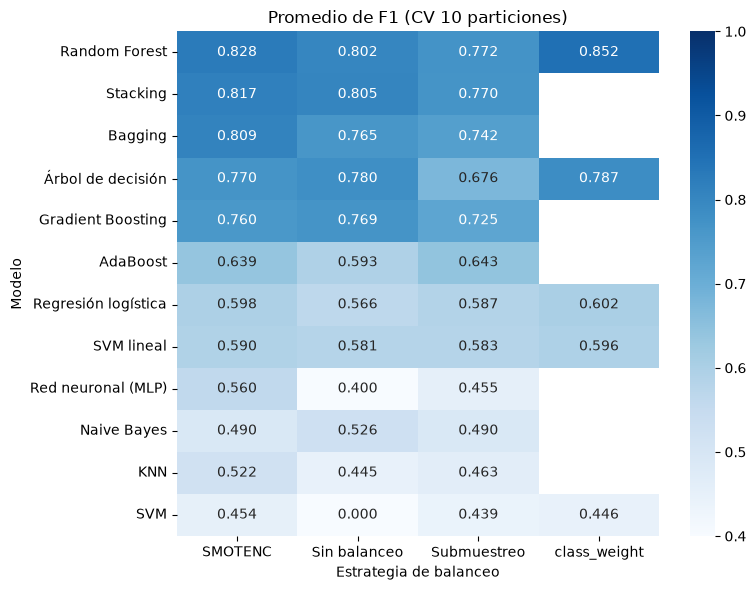

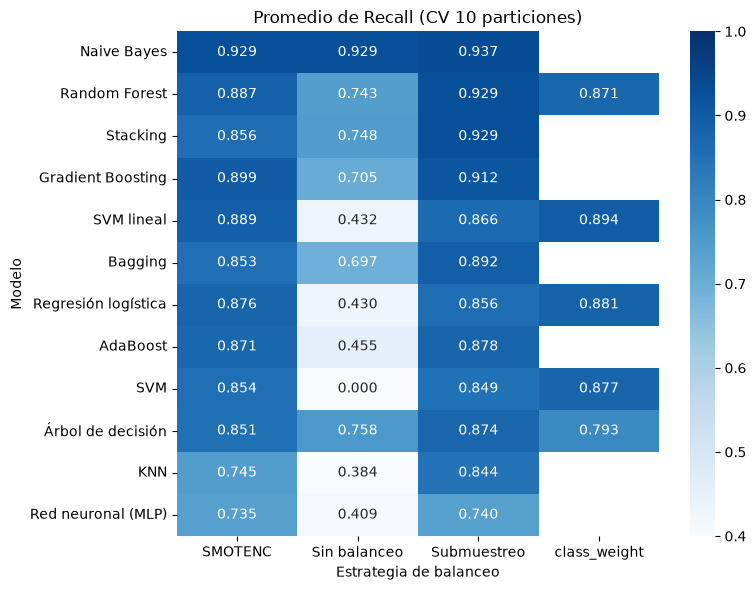

In [78]:
if not REANUDAR_COMPARACION:
    # 1. Mapa de calor de F1 y Recall
    for metrica, nombre_archivo in [("F1", "03_heatmap_f1_modelo_estrategia.png"),
                                    ("Recall", "03_heatmap_recall_modelo_estrategia.png")]:
        pivote = tabla_modelos.pivot(index="Modelo", columns="Estrategia", values=metrica)
        # Ordenamos los modelos según su mejor desempeño en esa métrica
        orden = pivote.max(axis=1).sort_values(ascending=False).index
        pivote = pivote.reindex(orden)

        plt.figure(figsize=(8, 6))
        sns.heatmap(pivote, annot=True, fmt=".3f", cmap="Blues", vmin=0.4, vmax=1.0)
        plt.title(f"Promedio de {metrica} (CV 10 particiones)")
        plt.ylabel("Modelo")
        plt.xlabel("Estrategia de balanceo")
        plt.tight_layout()
        if GUARDAR_FIGURAS:
            plt.savefig(RUTA_FIGURAS + nombre_archivo, dpi=150)
        plt.show()


Graficamos la distribución del $F_1$ en las 10 particiones para los mejores modelos para evaluar su estabilidad frente a variaciones en los datos.

/var/folders/y4/93gqwfgd1qxbv26dg4yd81ym0000gn/T/ipykernel_32682/1925472541.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_box, x="Modelo", y="F1", palette="Blues_r")


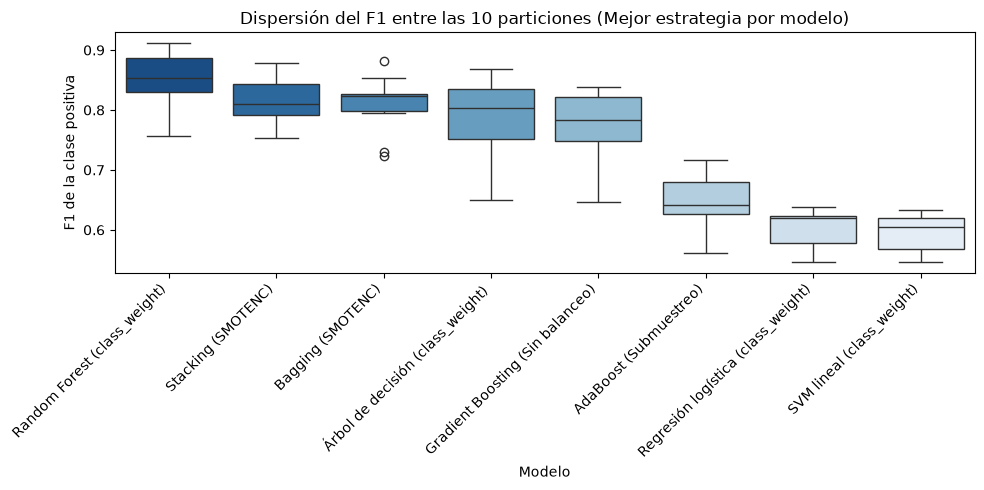

In [79]:
if not REANUDAR_COMPARACION:
    # Tomamos la mejor combinación de cada modelo
    mejores_por_modelo = tabla_modelos.drop_duplicates(subset="Modelo").head(8)

    datos_box = []
    for _, fila in mejores_por_modelo.iterrows():
        for val in fila["F1_por_particion"]:
            datos_box.append({
                "Modelo": f"{fila['Modelo']} ({fila['Estrategia']})",
                "F1": val
            })

    df_box = pd.DataFrame(datos_box)

    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_box, x="Modelo", y="F1", palette="Blues_r")
    plt.xticks(rotation=45, ha="right")
    plt.title("Dispersión del F1 entre las 10 particiones (Mejor estrategia por modelo)")
    plt.ylabel("F1 de la clase positiva")
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "03_boxplot_f1_por_particion.png", dpi=150)
    plt.show()


Por último, analizamos la relación entre Accuracy y $F_1$ para verificar el comportamiento de los modelos frente al desbalance.

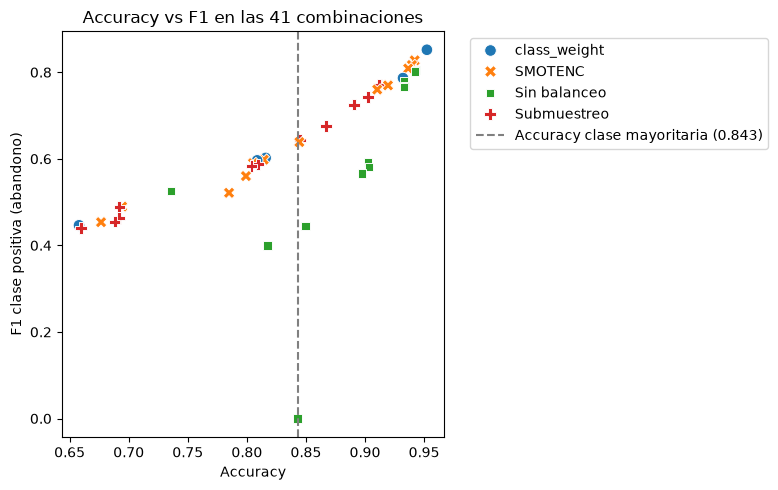

In [80]:
if not REANUDAR_COMPARACION:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=tabla_modelos,
        x="Accuracy",
        y="F1",
        hue="Estrategia",
        style="Estrategia",
        s=70
    )

    # Línea base de un clasificador mayoritario (siempre dice permanencia)
    proporcion_mayoritaria = (y_train == 0).mean()
    plt.axvline(proporcion_mayoritaria, color="gray", linestyle="--",
                label=f"Accuracy clase mayoritaria ({proporcion_mayoritaria:.3f})")

    plt.title("Accuracy vs F1 en las 41 combinaciones")
    plt.xlabel("Accuracy")
    plt.ylabel("F1 clase positiva (abandono)")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    if GUARDAR_FIGURAS:
        plt.savefig(RUTA_FIGURAS + "03_accuracy_vs_f1.png", dpi=150)
    plt.show()


### Selección de los tres mejores candidatos

Seleccionamos las **3 mejores combinaciones correspondientes a modelos distintos** para pasar a la fase de ajuste de hiperparámetros y evaluación final en la sección final.

In [81]:
if not REANUDAR_COMPARACION:
    candidatos = tabla_modelos.drop_duplicates(subset="Modelo").head(3).reset_index(drop=True)

    mejor_f1 = candidatos.loc[0, "F1"]
    mejor_std = candidatos.loc[0, "F1_std"]
    distancias = []
    for i in range(len(candidatos)):
        distancias.append((mejor_f1 - candidatos.loc[i, "F1"]) / mejor_std)
    candidatos["Distancia_al_mejor_en_desviaciones"] = distancias

    columnas_candidatos = [
        "Modelo", "Estrategia", "F1", "F1_std", "Recall", "Precision", "ROC_AUC",
        "Accuracy", "Distancia_al_mejor_en_desviaciones"
    ]

    if GUARDAR_TABLAS:
        candidatos[columnas_candidatos].to_csv(RUTA_RESULTADOS + "03_candidatos.csv", index=False)
    display(candidatos[columnas_candidatos].round(3))


,Modelo,Estrategia,F1,F1_std,Recall,Precision,ROC_AUC,Accuracy,Distancia_al_mejor_en_desviaciones
0,Random Forest,class_weight,0.852,0.048,0.871,0.835,0.979,0.952,0.000
1,Stacking,SMOTENC,0.817,0.043,0.856,0.783,0.971,0.940,0.733
2,Bagging,SMOTENC,0.809,0.050,0.853,0.769,0.959,0.937,0.901


### Punto de guardado opcional

Con `GUARDAR_PUNTO_COMPARACION=True` se guarda un único archivo para continuar desde el ajuste. Incluye la partición reservada, candidatos y preparación; no contiene un modelo final. No es necesario para ejecutar normalmente.

In [82]:
if not REANUDAR_COMPARACION and GUARDAR_PUNTO_COMPARACION:
    punto = {
        "version_flujo": VERSION_FLUJO,
        "huella_datos": huella_datos,
        "versiones": versiones,
        "train": train,
        "test": test,
        "decisiones": decisiones,
        "candidatos": candidatos,
        "tabla_modelos": tabla_modelos,
        "particiones_cv": particiones_cv,
        "posiciones_cat": posiciones_cat,
        "indices_train_originales": indices_train_originales,
        "indices_test_originales": indices_test_originales
    }
    joblib.dump(punto, RUTA_PUNTO)
    print("Punto de comparación guardado:", RUTA_PUNTO)


## 4. Ajuste, evaluación y exportación

Continuamos con los objetos en memoria o, si se solicitó, recuperamos el punto de comparación. La reanudación comprueba la huella del original, la versión del flujo y las dependencias.

El F1 ajustado es una métrica de selección sobre train. La media y desviación del modelo previo al ajuste se reportan por separado; no se combinan como un F1 ajustado ± desviación. No hay validación anidada.

In [83]:
if REANUDAR_COMPARACION:
    punto = joblib.load(RUTA_PUNTO)
    if punto["version_flujo"] != VERSION_FLUJO or punto["huella_datos"] != huella_datos or punto["versiones"] != versiones:
        raise ValueError("El punto no corresponde al flujo, datos o dependencias actuales. Ejecuta de nuevo sin reanudar.")
    train = punto["train"]
    test = punto["test"]
    decisiones = punto["decisiones"]
    candidatos = punto["candidatos"]
    tabla_modelos = punto["tabla_modelos"]
    particiones_cv = punto["particiones_cv"]
    posiciones_cat = punto["posiciones_cat"]
    indices_train_originales = punto["indices_train_originales"]
    indices_test_originales = punto["indices_test_originales"]
    X_train = train.drop(columns="abandono")
    y_train = train["abandono"]
    X_test = test.drop(columns="abandono")
    y_test = test["abandono"]
    plantilla = decisiones["preprocesamiento"]
    columnas_entrada = list(X_train.columns)
    print("Comparación recuperada; se continúa desde el ajuste.")
display(candidatos[["Modelo", "Estrategia", "F1", "Recall", "Precision"]].round(4))


,Modelo,Estrategia,F1,Recall,Precision
0,Random Forest,class_weight,0.8519,0.8712,0.8347
1,Stacking,SMOTENC,0.8167,0.8560,0.7830
2,Bagging,SMOTENC,0.8087,0.8534,0.7693


### Grillas de los candidatos seleccionados

Se obtienen del mismo catálogo validado antes de la comparación.

In [84]:
for i in range(len(candidatos)):
    mod = candidatos.loc[i, "Modelo"]
    est = candidatos.loc[i, "Estrategia"]
    print(f"{mod} ({est}) -> {obtener_grilla(mod, est)}")


Random Forest (class_weight) -> {'modelo__n_estimators': [200, 300], 'modelo__max_depth': [10, 15, None], 'modelo__min_samples_leaf': [1, 2]}
Stacking (SMOTENC) -> {'modelo__final_estimator__C': [0.1, 1.0, 10.0], 'balanceo__k_neighbors': [3, 5]}
Bagging (SMOTENC) -> {'modelo__n_estimators': [10, 50], 'modelo__max_samples': [0.7, 1.0], 'balanceo__k_neighbors': [3, 5]}


### Ejecución del ajuste sobre los tres mejores modelos

Ejecutamos el procedimiento completo sobre los 3 candidatos y comparamos su desempeño en validación cruzada con probabilidades calibradas.

In [85]:
rows_ajuste = []
resultados_finales = {}

for i in range(len(candidatos)):
    nombre_m = candidatos.loc[i, "Modelo"]
    estrategia_m = candidatos.loc[i, "Estrategia"]
    print(f"\nAjustando: {nombre_m} ({estrategia_m})...")

    pipeline_cand = armar_pipeline(plantilla, buscar_modelo(nombre_m), estrategia_m, posiciones_cat)
    grilla_cand = obtener_grilla(nombre_m, estrategia_m)

    resultado = ajustar_candidato(pipeline_cand, grilla_cand, X_train, y_train, particiones_cv)
    resultados_finales[nombre_m] = resultado

    pred_cv = (resultado["probabilidades_cv"] >= resultado["umbral"]).astype(int)
    met_cv = calcular_metricas(y_train, pred_cv, resultado["probabilidades_cv"])

    rows_ajuste.append({
        "Modelo": nombre_m,
        "Estrategia": estrategia_m,
        "F1_03": candidatos.loc[i, "F1"],
        "F1_03_Std": float(candidatos.loc[i, "F1_std"]),
        "F1_Seleccion_Ajustado": met_cv["F1"],
        "Umbral": resultado["umbral"],
        "Recall": met_cv["Recall"],
        "Precision": met_cv["Precision"],
        "ROC_AUC": met_cv["ROC_AUC"],
        "Brier": met_cv["Brier"],
        "Mejores_parametros": str(resultado["parametros"])
    })
    print(f"Mejores parámetros: {resultado['parametros']}")
    print(f"Umbral óptimo: {resultado['umbral']} -> F1 selección: {met_cv['F1']:.3f} | Recall: {met_cv['Recall']:.3f} | Precisión: {met_cv['Precision']:.3f}")

tabla_ajuste = pd.DataFrame(rows_ajuste).sort_values("F1_Seleccion_Ajustado", ascending=False).reset_index(drop=True)
if GUARDAR_TABLAS:
    tabla_ajuste.to_csv(RUTA_RESULTADOS + "ajuste_hiperparametros.csv", index=False)
display(tabla_ajuste.round(3))



Ajustando: Random Forest (class_weight)...
Mejores parámetros: {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
Umbral óptimo: 0.29 -> F1 selección: 0.859 | Recall: 0.922 | Precisión: 0.804

Ajustando: Stacking (SMOTENC)...
Mejores parámetros: {'balanceo__k_neighbors': 3, 'modelo__final_estimator__C': 10.0}
Umbral óptimo: 0.22 -> F1 selección: 0.832 | Recall: 0.904 | Precisión: 0.770

Ajustando: Bagging (SMOTENC)...
Mejores parámetros: {'balanceo__k_neighbors': 5, 'modelo__max_samples': 0.7, 'modelo__n_estimators': 50}
Umbral óptimo: 0.27 -> F1 selección: 0.817 | Recall: 0.869 | Precisión: 0.771


,Modelo,Estrategia,F1_03,F1_03_Std,F1_Seleccion_Ajustado,Umbral,Recall,Precision,ROC_AUC,Brier,Mejores_parametros
0,Random Forest,class_weight,0.852,0.048,0.859,0.29,0.922,0.804,0.980,0.040,"{'modelo__max_depth': 15, 'modelo__min_samples..."
1,Stacking,SMOTENC,0.817,0.043,0.832,0.22,0.904,0.770,0.971,0.044,"{'balanceo__k_neighbors': 3, 'modelo__final_es..."
2,Bagging,SMOTENC,0.809,0.050,0.817,0.27,0.869,0.771,0.969,0.050,"{'balanceo__k_neighbors': 5, 'modelo__max_samp..."


### Selección del modelo final y análisis de umbral

Elegimos como modelo definitivo el clasificador con mayor $F_1$ en validación cruzada. Analizamos su curva de métricas ($F_1$, Recall y Precisión) según el umbral de decisión.

Modelo seleccionado como FINAL: Random Forest (class_weight)
Umbral de alerta asignado: 0.29


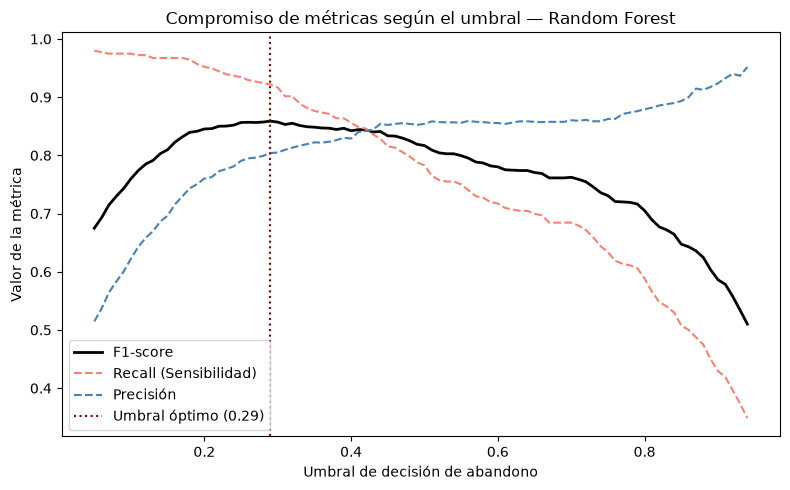

In [86]:
nombre_final = tabla_ajuste.loc[0, "Modelo"]
estrategia_final = tabla_ajuste.loc[0, "Estrategia"]
resultado_final = resultados_finales[nombre_final]
umbral_final = resultado_final["umbral"]

print(f"Modelo seleccionado como FINAL: {nombre_final} ({estrategia_final})")
print(f"Umbral de alerta asignado: {umbral_final}")

# Gráfico de F1, Recall y Precisión en función del umbral
tabla_u = resultado_final["tabla_umbrales"]
plt.figure(figsize=(8, 5))
plt.plot(tabla_u["Umbral"], tabla_u["F1"], label="F1-score", color="black", lw=2)
plt.plot(tabla_u["Umbral"], tabla_u["Recall"], label="Recall (Sensibilidad)", color="salmon", ls="--")
plt.plot(tabla_u["Umbral"], tabla_u["Precision"], label="Precisión", color="steelblue", ls="--")
plt.axvline(umbral_final, color="darkred", ls=":", label=f"Umbral óptimo ({umbral_final})")
plt.title(f"Compromiso de métricas según el umbral — {nombre_final}")
plt.xlabel("Umbral de decisión de abandono")
plt.ylabel("Valor de la métrica")
plt.legend()
plt.tight_layout()
if GUARDAR_FIGURAS:
    plt.savefig(RUTA_FIGURAS + "04_f1_recall_precision_vs_umbral.png", dpi=150)
plt.show()


### Evaluación final en prueba

Usamos la partición test reservada en memoria. El modelo y el umbral ya están elegidos usando train; no se modifican después de esta evaluación.

In [87]:
X_test = test[columnas_entrada]
y_test = test["abandono"]

probabilidades_test = predecir_probabilidad(resultado_final, X_test)
y_pred_test = (probabilidades_test >= umbral_final).astype(int)

print(f"Registros de prueba: {len(test)} | Casos de abandono reales: {int(y_test.sum())} ({y_test.mean()*100:.2f}%)")
print("\nReporte de Clasificación en Conjunto de Prueba:")
print(classification_report(y_test, y_pred_test, target_names=["Permanece", "Abandona"], digits=3))

metricas_test = calcular_metricas(y_test, y_pred_test, probabilidades_test)
print("\nMétricas consolidadas en test:")
for k, v in metricas_test.items():
    print(f" - {k:<20}: {v:.4f}")


Registros de prueba: 630 | Casos de abandono reales: 99 (15.71%)

Reporte de Clasificación en Conjunto de Prueba:
              precision    recall  f1-score   support

   Permanece      0.990     0.968     0.979       531
    Abandona      0.847     0.949     0.895        99

    accuracy                          0.965       630
   macro avg      0.919     0.959     0.937       630
weighted avg      0.968     0.965     0.966       630


Métricas consolidadas en test:
 - F1                  : 0.8952
 - Recall              : 0.9495
 - Precision           : 0.8468
 - ROC_AUC             : 0.9872
 - Precision_promedio  : 0.9191
 - Accuracy            : 0.9651
 - Brier               : 0.0325


Visualizamos la matriz de confusión y las curvas ROC y Precisión-Recall en el conjunto de prueba.

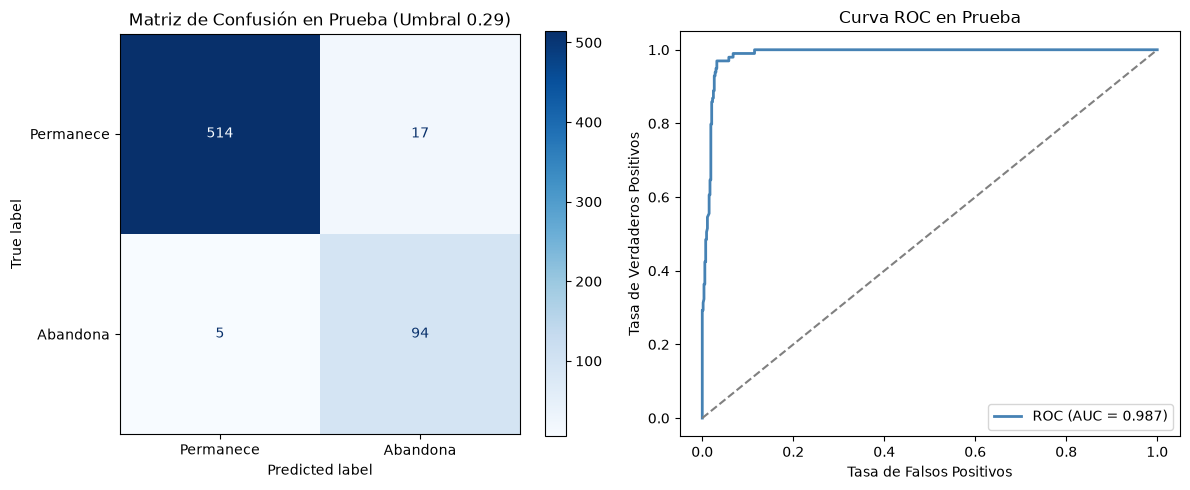

Abandonos detectados correctamente (True Positives): 94 de 99 (94.9%)
Falsas alarmas (False Positives): 17 entre 531 clientes que permanecen (3.2%)


In [88]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test,
    display_labels=["Permanece", "Abandona"],
    cmap="Blues",
    values_format="d",
    ax=ejes[0]
)
ejes[0].set_title(f"Matriz de Confusión en Prueba (Umbral {umbral_final})")

# 2. Curvas ROC y Precision-Recall
fpr, tpr, _ = roc_curve(y_test, probabilidades_test)
prec_c, rec_c, _ = precision_recall_curve(y_test, probabilidades_test)

ejes[1].plot(fpr, tpr, color="steelblue", lw=2, label=f"ROC (AUC = {metricas_test['ROC_AUC']:.3f})")
ejes[1].plot([0, 1], [0, 1], color="gray", ls="--")
ejes[1].set_xlabel("Tasa de Falsos Positivos")
ejes[1].set_ylabel("Tasa de Verdaderos Positivos")
ejes[1].set_title("Curva ROC en Prueba")
ejes[1].legend()

plt.tight_layout()
if GUARDAR_FIGURAS:
    plt.savefig(RUTA_FIGURAS + "04_matriz_confusion_test.png", dpi=150)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print(f"Abandonos detectados correctamente (True Positives): {tp} de {tp + fn} ({tp/(tp+fn)*100:.1f}%)")
print(f"Falsas alarmas (False Positives): {fp} entre {tn + fp} clientes que permanecen ({fp/(tn+fp)*100:.1f}%)")


### Exportación del modelo final y metadatos

Guardamos el artefacto del modelo (`models/modelo_final.joblib`) y el archivo de configuración `metadata_modelo.json`.
La estructura exportada es exactamente la requerida por la aplicación interactiva (`app.py`), permitiendo evaluar clientes individuales y priorizar archivos CSV.

In [89]:
artefacto = {
    "pipeline": resultado_final["pipeline"],
    "calibrador": resultado_final["calibrador"],
    "umbral": float(umbral_final),
    "columnas_entrada": columnas_entrada,
    "modelo": nombre_final,
    "estrategia_balanceo": estrategia_final
}
joblib.dump(artefacto, RUTA_MODELOS + "modelo_final.joblib")

hiperparametros_dict = {}
for k, v in resultado_final["parametros"].items():
    hiperparametros_dict[k] = str(v)

metricas_test_dict = {}
for k, v in metricas_test.items():
    metricas_test_dict[k] = float(v)

metricas_seleccion_dict = {
    "F1": float(tabla_ajuste.loc[0, "F1_Seleccion_Ajustado"]),
    "Recall": float(tabla_ajuste.loc[0, "Recall"]),
    "Precision": float(tabla_ajuste.loc[0, "Precision"]),
    "ROC_AUC": float(tabla_ajuste.loc[0, "ROC_AUC"]),
    "Brier": float(tabla_ajuste.loc[0, "Brier"])
}

metadata = {
    "modelo": nombre_final,
    "estrategia_balanceo": estrategia_final,
    "preprocesamiento": decisiones["alternativa"],
    "calibracion": "sigmoide (Platt scaling)",
    "columnas_entrada": columnas_entrada,
    "umbral": float(umbral_final),
    "hiperparametros": hiperparametros_dict,
    "metricas_seleccion_entrenamiento": metricas_seleccion_dict,
    "metricas_comparacion_previa": {
        "F1_media": float(tabla_ajuste.loc[0, "F1_03"]),
        "F1_desviacion": float(tabla_ajuste.loc[0, "F1_03_Std"]),
        "procedimiento": "Modelo previo al ajuste: CV estratificada de diez particiones, sin grupos"
    },
    "procedimiento_seleccion": "Ajuste de hiperparámetros, calibración OOF y selección de umbral sobre train; sin validación anidada",
    "procedimiento_calibracion": "Sigmoide ajustada con puntajes fuera de pliegue y conservada para inferencia con el umbral elegido",
    "contexto_test": "Conjunto reservado que ya se consultó para diagnosticar la calibración; la reevaluación no es una validación nueva intacta",
    "metricas_test": metricas_test_dict,
    "intervalos_bootstrap_test_95": {},
    "fecha_entrenamiento": datetime.datetime.now().isoformat(timespec="seconds"),
    "version_sklearn": sklearn.__version__,
    "version_imblearn": imblearn.__version__
}

with open(RUTA_MODELOS + "metadata_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Artefactos exportados exitosamente:")
print(" -", RUTA_MODELOS + "modelo_final.joblib")
print(" -", RUTA_MODELOS + "metadata_modelo.json")


Artefactos exportados exitosamente:
 - ./models/modelo_final.joblib
 - ./models/metadata_modelo.json


### Archivos de apoyo para la app

Guardamos train y test solo como entradas de la app, al final del flujo. Actualizamos la priorización con las probabilidades de la evaluación final, sin volver a entrenar ni elegir otro umbral.

In [90]:
train.to_csv(RUTA_DATOS + "train.csv", index=False)
test.to_csv(RUTA_DATOS + "test.csv", index=False)
orden_riesgo = np.argsort(-probabilidades_test, kind="stable")
rows_prioridad = []
for fraccion in [0.05, 0.10, 0.20, 0.30]:
    cantidad = int(np.ceil(len(y_test) * fraccion))
    abandonos = int(y_test.iloc[orden_riesgo[:cantidad]].sum())
    precision_prioridad = abandonos / cantidad
    rows_prioridad.append({
        "Fraccion_contactada": fraccion,
        "Clientes": cantidad,
        "Precision": precision_prioridad,
        "Recall": abandonos / int(y_test.sum()),
        "Lift": precision_prioridad / y_test.mean()
    })
priorizacion_test = pd.DataFrame(rows_prioridad)
priorizacion_test.to_csv(RUTA_RESULTADOS + "04_priorizacion_test.csv", index=False)
display(priorizacion_test.round(4))


,Fraccion_contactada,Clientes,Precision,Recall,Lift
0,0.05,32,0.9688,0.3131,6.1648
1,0.10,63,0.8730,0.5556,5.5556
2,0.20,126,0.7619,0.9697,4.8485
3,0.30,189,0.5238,1.0000,3.3333


### Verificación de recarga del modelo

Verificamos que el archivo `modelo_final.joblib` guardado en disco se pueda cargar y genere exactamente las mismas probabilidades y predicciones que el modelo original en memoria.

In [91]:
artefacto_cargado = joblib.load(RUTA_MODELOS + "modelo_final.joblib")

puntajes_recargados = obtener_puntaje(artefacto_cargado["pipeline"], X_test)
prob_recargadas = artefacto_cargado["calibrador"].predict_proba(puntajes_recargados.reshape(-1, 1))[:, 1]
pred_recargadas = (prob_recargadas >= artefacto_cargado["umbral"]).astype(int)

diferencia_maxima = np.max(np.abs(probabilidades_test - prob_recargadas))
coincidencia_exacta = np.array_equal(y_pred_test, pred_recargadas)

print(f"Diferencia numérica máxima entre predicciones: {diferencia_maxima:.2e}")
print(f"¿Predicciones discretas idénticas al 100%?: {coincidencia_exacta}")


Diferencia numérica máxima entre predicciones: 0.00e+00
¿Predicciones discretas idénticas al 100%?: True


### Conclusiones de esta ejecución

La tabla resume los resultados calculados en esta ejecución. Las métricas de selección no equivalen a validación anidada. El test ya fue consultado al diagnosticar el error; estos resultados verifican la corrección y no son una nueva validación intacta.

In [92]:
resumen_final = pd.DataFrame([{
    "Modelo": nombre_final,
    "Estrategia": estrategia_final,
    "Umbral": umbral_final,
    "F1_test": metricas_test["F1"],
    "Recall_test": metricas_test["Recall"],
    "Precision_test": metricas_test["Precision"],
    "ROC_AUC_test": metricas_test["ROC_AUC"],
    "Abandonos_detectados": int(tp),
    "Abandonos_reales": int(tp + fn)
}])
display(resumen_final.round(4))


,Modelo,Estrategia,Umbral,F1_test,Recall_test,Precision_test,ROC_AUC_test,Abandonos_detectados,Abandonos_reales
0,Random Forest,class_weight,0.29,0.8952,0.9495,0.8468,0.9872,94,99
